# 01 — Datenpipeline

Laden, Feature Engineering, Encoding, stratifizierter Split, Skalierung und explorative Analyse der vier betrachteten Zielspalten (TWF, HDF, PWF, OSF). RNF wird bewusst ausgeschlossen (siehe `docs/implementation_notes.md`).

In [1]:
# Projekt-Root ins Suchpfad aufnehmen, damit src/ importierbar ist
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.paths import figure_path, result_path
from src.visualize import draw_failure_scatter
from src.data import (
    add_engineered_features, encode_type, split_data, fit_scaler, apply_scaler,
    TARGET_COLUMNS, EXCLUDED_TARGET, FEATURE_COLUMNS, RAW_FEATURE_COLUMNS, BINARY_TARGET_COLUMN
)

sns.set_theme(style="whitegrid")
BLUE, RED = "#3b4cc0", "#b40426"  # Farbschema, konsistent über alle Notebooks/die Doku hinweg

## 1. Rohdaten laden

Offizielle UCI-Quelle (archive.ics.uci.edu/dataset/601).

In [2]:
df = pd.read_csv("../data/raw/ai4i2020.csv")
print(f"Rohdaten geladen: {df.shape}")
df.head(3)

Rohdaten geladen: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


## 2. Fehlende Werte prüfen

In [3]:
# Summe über alle Spalten und Zeilen -- ein einzelner Wert genügt hier als Sanity Check
print("Fehlende Werte insgesamt:", df.isnull().sum().sum())

Fehlende Werte insgesamt: 0


## 3. Verteilung der Rohmerkmale

Die sechs numerischen bzw. kategorischen Rohmerkmale, vor jeder Transformation, eingefärbt nach dem übergeordneten Binärlabel `Machine failure`.

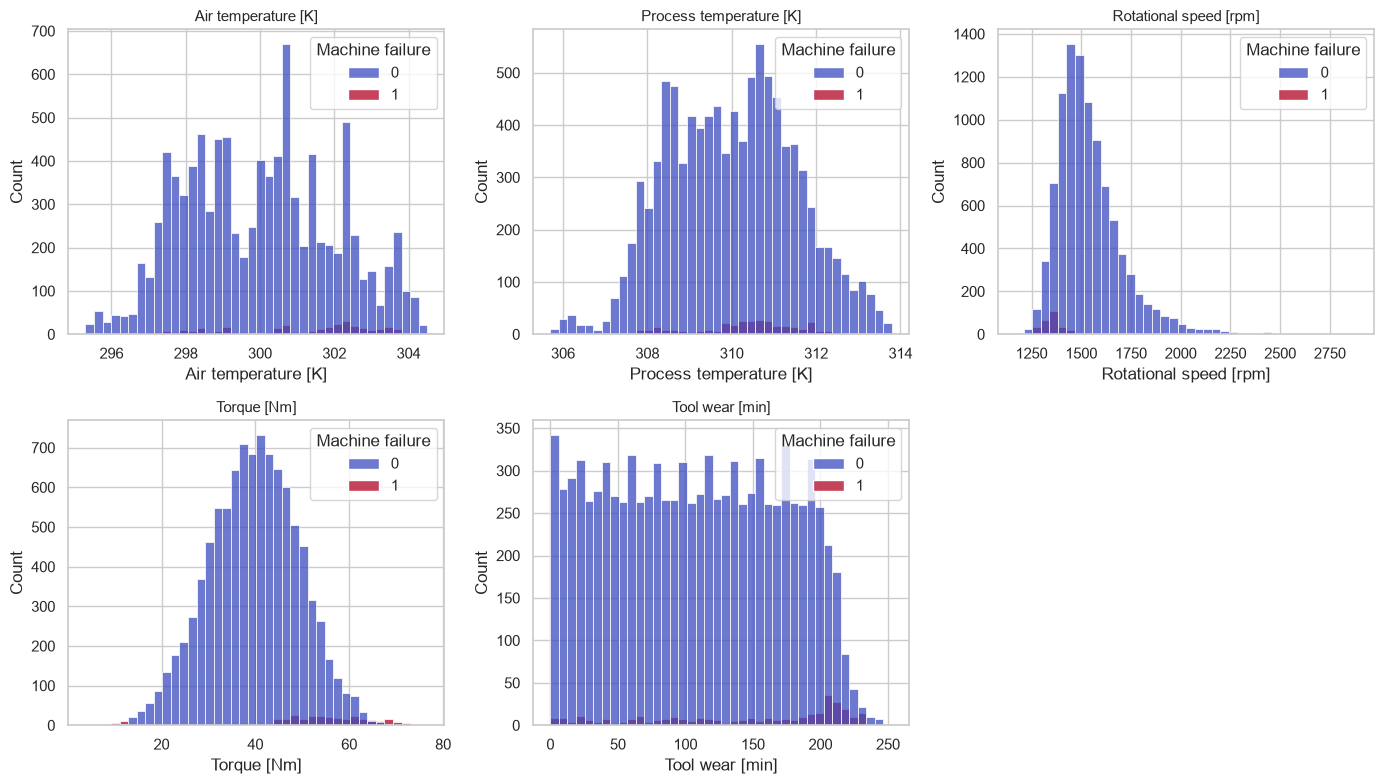

In [4]:
# Fünf numerische Rohmerkmale als Histogramme, je 0/1 der Zielvariable eingefärbt;
# Type (kategorisch) wird hier ausgelassen, da ein Histogramm dafür nicht passt
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for ax, col in zip(axes, RAW_FEATURE_COLUMNS):
    sns.histplot(data=df, x=col, hue="Machine failure", ax=ax, bins=40,
                 palette={0: BLUE, 1: RED}, alpha=0.75)
    ax.set_title(col, fontsize=11)
axes[5].axis("off")  # sechstes Feld bleibt leer, da nur 5 numerische Merkmale geplottet werden

plt.tight_layout()
plt.savefig(figure_path("eda", "feature_distributions.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Feature Engineering + Encoding

Zwei zusätzliche, physikalisch motivierte Merkmale (`Power [W]`, `Temperature diff [K]`) sowie One-Hot-Encoding von `Type`.

In [5]:
# Muss vor der Skalierung erfolgen, da die neuen Spalten Teil von FEATURE_COLUMNS sind
df = add_engineered_features(df)
# Type (L/M/H) -> drei Binärspalten type_L/type_M/type_H
df = encode_type(df)
print(f"Nach Feature Engineering + Encoding: {df.shape}")

Nach Feature Engineering + Encoding: (10000, 18)


## 5. Korrelationsmatrix

Inklusive der beiden abgeleiteten Merkmale, um ihre Beziehung zu den Rohmerkmalen zu zeigen, aus denen sie berechnet werden.

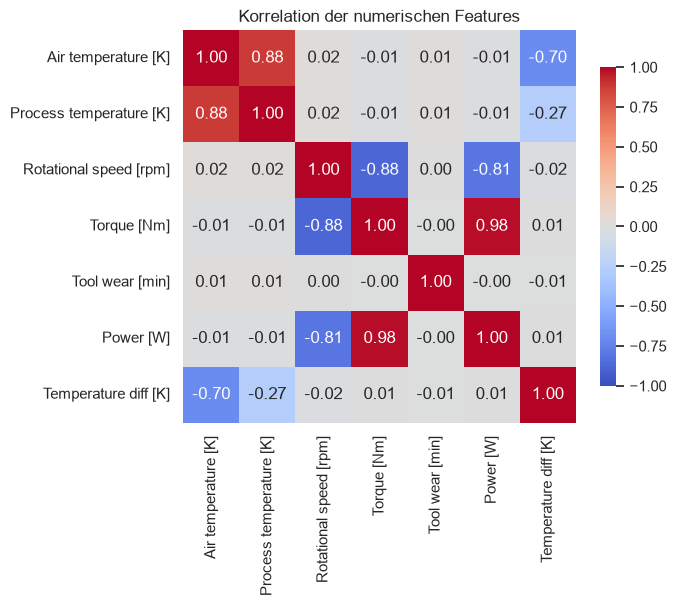

In [6]:
corr = df[FEATURE_COLUMNS].corr()

fig, ax = plt.subplots(figsize=(7, 6))
cmap = "coolwarm"
sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap, center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Korrelation der numerischen Features")
plt.tight_layout()
plt.savefig(figure_path("eda", "correlation_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

## 6. Verteilung der abgeleiteten Merkmale

`Power [W]` und `Temperature diff [K]` einzeln betrachtet.

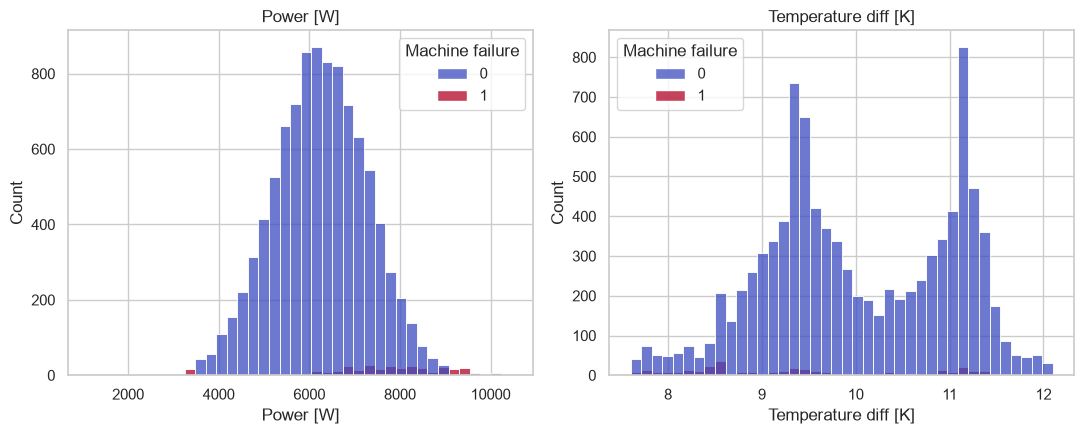

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col in zip(axes, ["Power [W]", "Temperature diff [K]"]):
    sns.histplot(data=df, x=col, hue="Machine failure", ax=ax, bins=40,
                 palette={0: BLUE, 1: RED}, alpha=0.75)
    ax.set_title(col, fontsize=12)
plt.tight_layout()
plt.savefig(figure_path("eda", "engineered_feature_distributions.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Verteilung der vier Zielspalten

Wichtig: Diese vier Modi können **gleichzeitig** aktiv sein (echtes Multi-Label, kein exklusives Mehrklassenproblem).

In [8]:
# Absolute Häufigkeit + Anteil je Zielspalte
print("Häufigkeit je Fehlermodus:")
for col in TARGET_COLUMNS:
    print(f"  {col}: {df[col].sum()} positive Fälle ({df[col].mean()*100:.2f}%)")
print(f"  ({EXCLUDED_TARGET}, ausgeschlossen): {df[EXCLUDED_TARGET].sum()} Fälle")

# Zeilensumme über die 4 Zielspalten: 0 = kein Ausfall, 1 = genau ein Modus aktiv,
# 2/3 = mehrere Modi gleichzeitig aktiv (siehe Zellen-Ausgabe unten)
label_sum = df[TARGET_COLUMNS].sum(axis=1)
print("\nAnzahl gleichzeitig aktiver Modi:")
print(label_sum.value_counts().sort_index())

Häufigkeit je Fehlermodus:
  TWF: 46 positive Fälle (0.46%)
  HDF: 115 positive Fälle (1.15%)
  PWF: 95 positive Fälle (0.95%)
  OSF: 98 positive Fälle (0.98%)
  (RNF, ausgeschlossen): 19 Fälle

Anzahl gleichzeitig aktiver Modi:
0    9670
1     307
2      22
3       1
Name: count, dtype: int64


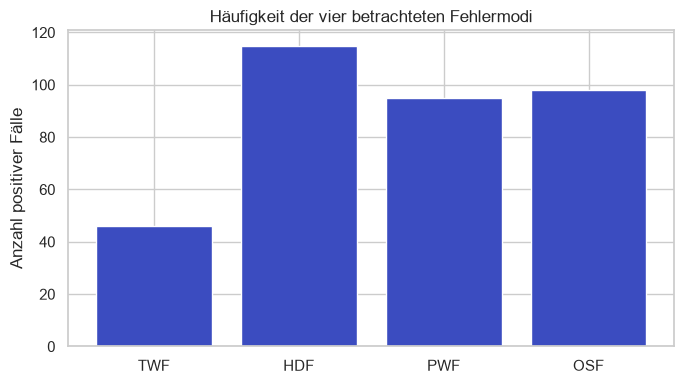

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = [df[col].sum() for col in TARGET_COLUMNS]
ax.bar(TARGET_COLUMNS, counts, color=BLUE)
ax.set_title("Häufigkeit der vier betrachteten Fehlermodi")
ax.set_ylabel("Anzahl positiver Fälle")
plt.tight_layout()
plt.savefig(figure_path("eda", "target_distribution_multilabel.png"), dpi=150, bbox_inches="tight")
plt.show()

## 8. Stratifizierter Split (70/15/15)

Echte Multi-Label-Stratifizierung (`MultilabelStratifiedShuffleSplit`): alle vier Zielspalten werden gleichzeitig balanciert, nicht nur das übergeordnete Binärlabel `Machine failure`.

In [10]:
# 70/15/15-Split; Anteile je Zielspalte werden unten je Split ausgegeben,
# um die Qualität der Multi-Label-Stratifizierung zu prüfen
train, val, test = split_data(df)
print(f"Split: Train={len(train)}, Val={len(val)}, Test={len(test)}")
for name, split in [("Train", train), ("Val", val), ("Test", test)]:
    rates = {col: f"{split[col].mean()*100:.2f}%" for col in TARGET_COLUMNS}
    print(f"  {name}: {rates}")

Split: Train=7000, Val=1500, Test=1500
  Train: {'TWF': '0.46%', 'HDF': '1.16%', 'PWF': '0.96%', 'OSF': '0.97%'}
  Val: {'TWF': '0.47%', 'HDF': '1.13%', 'PWF': '0.93%', 'OSF': '1.00%'}
  Test: {'TWF': '0.47%', 'HDF': '1.13%', 'PWF': '0.93%', 'OSF': '1.00%'}


## 9. Zusammenhang von Merkmalen und Fehlermodi (Trainingsdaten)

Je Fehlermodus ein Streudiagramm zweier Merkmale: rot die Beobachtungen des Modus, grau Beobachtungen ohne Ausfall, blau Beobachtungen, die nur durch einen der übrigen Modi ausfallen. Verwendet wird nur der Trainingssplit.

In [11]:
draw_failure_scatter(
    train, TARGET_COLUMNS,
    panels=[
        ("HDF", "Temperature diff [K]", "Rotational speed [rpm]"),
        ("PWF", "Rotational speed [rpm]", "Torque [Nm]"),
        ("OSF", "Tool wear [min]", "Torque [Nm]"),
        ("TWF", "Tool wear [min]", "Torque [Nm]"),
    ],
    path=figure_path("eda", "failure_scatter.png"),
)

## 10. Skalierung (nur auf Trainingsdaten gefittet, Data Leakage vermeiden)

In [12]:
# StandardScaler nur auf Train fitten, dann auf alle drei Splits anwenden
scaler = fit_scaler(train)
train_scaled = apply_scaler(train, scaler)
val_scaled = apply_scaler(val, scaler)
test_scaled = apply_scaler(test, scaler)

# Verarbeitete Splits für die nachfolgenden Notebooks persistieren
train_scaled.to_csv("../data/processed/train.csv", index=False)
val_scaled.to_csv("../data/processed/val.csv", index=False)
test_scaled.to_csv("../data/processed/test.csv", index=False)

import pickle
with open("../models/scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
print("Verarbeitete Splits + Scaler gespeichert.")

Verarbeitete Splits + Scaler gespeichert.
